# رقيم · Raqim-OCR
**Fine-tuning a small vision-language model for hard Arabic handwriting recognition (Colab + Google Drive).**

| | |
|---|---|
| Base model | [`Qwen/Qwen3-VL-2B-Instruct`](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct) (~2B params, ~4.3 GB in bf16) |
| Dataset | [`aamijar/muharaf-public`](https://huggingface.co/datasets/aamijar/muharaf-public): historical handwritten Arabic manuscript lines (Muharaf, ~22k train / 1k val / 1.3k test) |
| Method | LoRA (language model + vision tower), bf16, batch size auto-tuned to a VRAM target |
| Metrics | CER / WER on the held-out test split, before vs. after fine-tuning |

**Why this data is hard:** cursive Ruq'ah and Naskh hands, 19th–21st century manuscripts, ink bleed, degraded paper, dialectal vocabulary and inconsistent spelling.

**Persistence:** the downloaded model/dataset copies, checkpoints, adapter and merged model are written under
`My Drive/Colab Notebooks/raqim-ocr/`. Restarting or deleting the runtime loses nothing; re-running the notebook resumes from the last checkpoint.

> **License note.** The Muharaf dataset is released under **CC BY-NC-SA 4.0** (non-commercial, share-alike). Models trained on it should carry the same terms, and the generated model card does so. Cite the Muharaf paper (Saeed et al., 2024, arXiv:2406.09630) when you publish.

**Runtime:** GPU required. L4 / A100 recommended (bf16). A T4 also works (automatic fp16 fallback), only slower.

## 1 · Install

In [1]:
!pip install -q -U "transformers>=4.57" "peft>=0.14" datasets accelerate jiwer "torchao>=0.16.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 2 · Drive project folder
Everything lives on Drive, nothing depends on the Colab instance disk.

In [2]:
import os
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_NAME = "Raqim_OCR_Arabic"
ROOT = Path("/content/drive/MyDrive/Colab Notebooks") / PROJECT_NAME
DIRS = {name: ROOT / name for name in ("assets", "checkpoints", "adapter", "merged", "reports")}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# Downloads and Arrow caches go to the LOCAL disk (writing big files straight to Drive corrupts them).
# Finished copies are then stored in Drive/assets, so a fresh runtime copies instead of re-downloading.
LOCAL = Path("/content/_local")
os.environ["HF_HOME"] = str(LOCAL / "hf_home")
os.environ["HF_DATASETS_CACHE"] = str(LOCAL / "hf_datasets")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # avoids VRAM fragmentation OOMs

import shutil
from huggingface_hub import HfApi, login, snapshot_download

# Log in now so a missing token fails here, not after hours of training.
try:
    from google.colab import userdata
    login(userdata.get("HF_TOKEN"))
except Exception:
    from huggingface_hub import notebook_login
    notebook_login()
HF_USER = HfApi().whoami()["name"]
HF_REPO = f"{HF_USER}/{PROJECT_NAME}"
print("Hugging Face user:", HF_USER, "| target repo:", HF_REPO)

def fetch(repo_id: str, repo_type: str) -> Path:
    # Return a local folder with the repo: restore from Drive if saved there, else download then back it up.
    name = repo_id.replace("/", "__")
    local, saved = LOCAL / "assets" / name, DIRS["assets"] / name
    if (local / ".complete").exists():
        return local
    shutil.rmtree(local, ignore_errors=True)
    if (saved / ".complete").exists():
        shutil.copytree(saved, local)
    else:
        snapshot_download(repo_id, repo_type=repo_type, local_dir=local)
        (local / ".complete").touch()
        shutil.rmtree(saved, ignore_errors=True)
        shutil.copytree(local, saved, ignore=shutil.ignore_patterns(".cache"))
        (saved / ".complete").touch()
    (local / ".complete").touch()
    return local

print("Project folder:", ROOT)

Mounted at /content/drive
Hugging Face user: Youssefx64 | target repo: Youssefx64/Raqim_OCR_Arabic
Project folder: /content/drive/MyDrive/Colab Notebooks/Raqim_OCR_Arabic


## 3 · Configuration
All knobs in one place.

In [3]:
from dataclasses import dataclass

@dataclass
class Cfg:
    model_id: str = "Qwen/Qwen3-VL-2B-Instruct"
    dataset_id: str = "aamijar/muharaf-public"
    prompt: str = "Transcribe the Arabic handwriting in this image exactly as written."

    # image preprocessing
    min_height: int = 64        # upscale very small line crops
    max_side: int = 1280        # cap the longest side
    max_chars: int = 200        # drop abnormally long transcriptions

    # LoRA
    lora_r: int = 32
    lora_alpha: int = 64
    lora_dropout: float = 0.05
    train_vision: bool = True   # handwriting is a visual domain shift, so adapt the vision tower too

    # training
    epochs: int = 2
    lr: float = 1e-4
    effective_batch: int = 32
    target_vram_gb: float = 12.0     # batch size is auto-tuned to stay under this
    max_train_samples: int | None = None   # set e.g. 2000 for a quick smoke test
    n_eval: int = 300                # test samples used for the quick baseline eval
    seed: int = 42

cfg = Cfg()

## 4 · Data

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/22092 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1069 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1334 [00:00<?, ? examples/s]

{'train': 22091, 'validation': 1069, 'test': 1334}


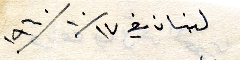

لبنان في ١٧/١٠/١٩٦٠


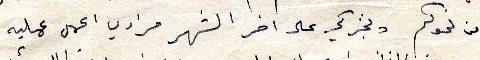

من نحوكم ونخبركي على اخر الشهر مرادي اعمل عمليه


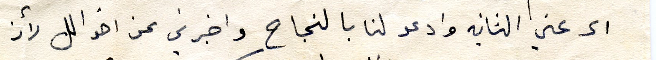

الى عني الثانيه وادعو لنا بالنجاح واخبرني عن اخوالك لأن


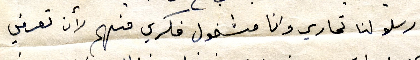

لم ارسلو لنا تحارير وانا مشغول فكري فيهم لأن تعرفي


In [4]:
import re, unicodedata
from datasets import load_dataset
from IPython.display import display

DATA_DIR = fetch(cfg.dataset_id, "dataset")
raw = load_dataset(
    "parquet",
    data_files={sp: sorted(str(p) for p in (DATA_DIR / "data").glob(f"{sp}-*.parquet")) for sp in ("train", "validation", "test")},
)

def clean(text: str) -> str:
    text = unicodedata.normalize("NFC", text or "")
    return re.sub(r"\s+", " ", text).strip()

ds = raw.filter(lambda t: 0 < len(clean(t)) <= cfg.max_chars, input_columns="text")
if cfg.max_train_samples:
    ds["train"] = ds["train"].shuffle(seed=cfg.seed).select(range(cfg.max_train_samples))

print({k: len(v) for k, v in ds.items()})
for i in range(4):
    ex = ds["train"][i]
    display(ex["image"])
    print(clean(ex["text"]))

## 5 · Model and processor

In [5]:
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor, set_seed

assert torch.cuda.is_available(), "Select a GPU runtime: Runtime > Change runtime type"
set_seed(cfg.seed)

# is_bf16_supported() returns True on T4 because bf16 is *emulated* there (extremely slow).
# Native bf16 needs compute capability >= 8.0 (A100 / L4 / H100); otherwise use fp16.
BF16 = torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if BF16 else torch.float16
print(torch.cuda.get_device_name(0), "| dtype:", DTYPE)
if not BF16:
    print("Pre-Ampere GPU detected -> fp16 mode. Consider cfg.epochs=1 or cfg.max_train_samples to shorten the run.")

MODEL_DIR = fetch(cfg.model_id, "model")
processor = AutoProcessor.from_pretrained(MODEL_DIR)
model = AutoModelForImageTextToText.from_pretrained(MODEL_DIR, dtype=DTYPE, device_map={"": 0})

Tesla T4 | dtype: torch.float16
Pre-Ampere GPU detected -> fp16 mode. Consider cfg.epochs=1 or cfg.max_train_samples to shorten the run.


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

## 6 · Preprocessing and collator
Loss is computed only on the transcription tokens (prompt and padding are masked).

In [6]:
from PIL import Image

def prepare_image(img: Image.Image) -> Image.Image:
    img = img.convert("RGB")
    w, h = img.size
    scale = max(1.0, cfg.min_height / h)
    if max(w, h) * scale > cfg.max_side:
        scale = cfg.max_side / max(w, h)
    if scale != 1.0:
        img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.Resampling.BICUBIC)
    return img

PROMPT = processor.apply_chat_template(
    [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": cfg.prompt}]}],
    add_generation_prompt=True,
    tokenize=False,
)
EOS = "<|im_end|>"
IM_START = processor.tokenizer.convert_tokens_to_ids("<|im_start|>")


class Collator:
    def __call__(self, batch):
        images = [prepare_image(ex["image"]) for ex in batch]
        texts = [PROMPT + clean(ex["text"]) + EOS for ex in batch]
        processor.tokenizer.padding_side = "right"
        enc = processor(text=texts, images=images, padding=True, return_tensors="pt")

        ids = enc["input_ids"]
        labels = ids.clone()
        # The assistant header is `<|im_start|> assistant \n` (3 tokens); mask everything up to its end.
        last_start = ids.shape[1] - 1 - (ids == IM_START).int().flip(1).argmax(1)
        for i, s in enumerate(last_start.tolist()):
            labels[i, : s + 3] = -100
        labels[enc["attention_mask"] == 0] = -100
        enc["labels"] = labels
        return enc


# Sanity check: the supervised tokens must be exactly "transcription + <|im_end|>".
check = Collator()([ds["train"][i] for i in range(2)])
for row in check["labels"]:
    print(repr(processor.tokenizer.decode(row[row != -100])))

'لبنان في ١٧/١٠/١٩٦٠<|im_end|>'
'من نحوكم ونخبركي على اخر الشهر مرادي اعمل عمليه<|im_end|>'


## 7 · LoRA

In [7]:
from peft import LoraConfig, get_peft_model

LLM_LAYERS = "q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj"
VIS_LAYERS = "qkv|proj|linear_fc1|linear_fc2"

pattern = rf".*language_model\..*\.({LLM_LAYERS})"
if cfg.train_vision:
    pattern = rf"({pattern})|(.*visual\..*\.({VIS_LAYERS}))"

model = get_peft_model(
    model,
    LoraConfig(
        r=cfg.lora_r,
        lora_alpha=cfg.lora_alpha,
        lora_dropout=cfg.lora_dropout,
        target_modules=pattern,
        task_type="CAUSAL_LM",
    ),
)
# fp16 training needs the trainable (LoRA) weights in fp32 for the grad scaler.
for p in model.parameters():
    if p.requires_grad:
        p.data = p.data.float()
model.print_trainable_parameters()

trainable params: 49,364,992 || all params: 2,176,897,024 || trainable%: 2.2677


## 8 · Auto-tune the batch size to the VRAM target
Runs a forward/backward pass on the *hardest* samples (longest transcriptions) at growing batch sizes and keeps the largest one whose peak memory stays under `cfg.target_vram_gb`.

In [8]:
import gc, math

def probe_batch_size(candidates=(2, 3, 4, 5, 6, 8, 10, 12, 16, 24, 32)):
    lengths = [len(t) for t in ds["train"]["text"]]
    hardest = sorted(range(len(lengths)), key=lengths.__getitem__)[-max(candidates):]
    collate, best = Collator(), candidates[0]
    model.train()
    for bs in candidates:
        gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        batch, peak = None, float("inf")
        try:
            batch = {k: v.to("cuda") for k, v in collate([ds["train"][i] for i in hardest[-bs:]]).items()}
            loss = model(**batch).loss
            assert torch.isfinite(loss), "Non-finite loss (fp16 overflow?). Use an L4/A100 GPU (bf16)."
            loss.backward()
            peak = torch.cuda.max_memory_allocated() / 2**30
        except torch.cuda.OutOfMemoryError:
            pass
        finally:
            model.zero_grad(set_to_none=True)
            del batch
        print(f"batch {bs:>2}: peak {peak:.1f} GB")
        if peak > cfg.target_vram_gb:
            break
        best = bs
    gc.collect(); torch.cuda.empty_cache()
    return best

BS = probe_batch_size()
ACC = math.ceil(cfg.effective_batch / BS)
print(f"-> per-device batch {BS} x grad-accum {ACC} = effective {BS * ACC}")

batch  2: peak 7.8 GB
batch  3: peak 9.6 GB
batch  4: peak 11.3 GB
batch  5: peak 13.1 GB
-> per-device batch 4 x grad-accum 8 = effective 32


## 9 · Evaluation helpers (CER / WER)

In [9]:
import pandas as pd
from jiwer import cer, wer

@torch.no_grad()
def transcribe(images, batch_size=8, max_new_tokens=160):
    model.eval()
    processor.tokenizer.padding_side = "left"
    outputs = []
    for i in range(0, len(images), batch_size):
        imgs = [prepare_image(im) for im in images[i : i + batch_size]]
        enc = processor(text=[PROMPT] * len(imgs), images=imgs, padding=True, return_tensors="pt").to("cuda")
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
        outputs += processor.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [clean(o) for o in outputs]


def evaluate(split, n=None):
    data = split if n is None else split.shuffle(seed=cfg.seed).select(range(min(n, len(split))))
    refs = [clean(t) for t in data["text"]]
    hyps = transcribe(list(data["image"]))
    metrics = {"CER": round(cer(refs, hyps), 4), "WER": round(wer(refs, hyps), 4), "n": len(refs)}
    return metrics, pd.DataFrame({"reference": refs, "prediction": hyps})

## 10 · Baseline (zero-shot, before fine-tuning)

In [10]:
baseline, _ = evaluate(ds["test"], cfg.n_eval)
print("Zero-shot baseline:", baseline)

Zero-shot baseline: {'CER': 1.1281, 'WER': 1.1144, 'n': 300}


## 11 · Train
Checkpoints (LoRA adapter + optimizer state) go to Drive every 100 steps. If the runtime disconnects, re-run the notebook: training resumes automatically when the config is unchanged; checkpoints from a different config are archived and training starts fresh.

In [11]:
import hashlib, json, time
from transformers import Trainer, TrainingArguments
from transformers.trainer_utils import get_last_checkpoint

CKPT = DIRS["checkpoints"]

# Resume only checkpoints produced by this exact config; archive anything else.
signature = hashlib.md5(json.dumps(cfg.__dict__, sort_keys=True).encode()).hexdigest()
sig_file = CKPT / "run_signature.txt"
if get_last_checkpoint(str(CKPT)) and not (sig_file.exists() and sig_file.read_text() == signature):
    archive = CKPT.with_name(f"checkpoints_old_{int(time.time())}")
    CKPT.rename(archive)
    CKPT.mkdir()
    print("Old checkpoints moved to", archive.name)
sig_file.write_text(signature)
resume_from = get_last_checkpoint(str(CKPT))
print("Resuming from", resume_from if resume_from else "-> starting a fresh run")


class SafeTrainer(Trainer):
    # Free cached VRAM around evaluation (this is where the previous run ran out of memory).
    def evaluate(self, *args, **kwargs):
        gc.collect(); torch.cuda.empty_cache()
        out = super().evaluate(*args, **kwargs)
        gc.collect(); torch.cuda.empty_cache()
        return out


args = TrainingArguments(
    output_dir=str(CKPT),
    per_device_train_batch_size=BS,
    per_device_eval_batch_size=max(1, BS // 2),
    gradient_accumulation_steps=ACC,
    num_train_epochs=cfg.epochs,
    learning_rate=cfg.lr,
    lr_scheduler_type="cosine",
    warmup_steps=50,
    bf16=BF16,
    fp16=not BF16,
    optim="adamw_torch_fused",
    max_grad_norm=1.0,
    logging_steps=25,
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    prediction_loss_only=True,       # never materialise the 150k-vocab logits during eval
    dataloader_num_workers=2,
    remove_unused_columns=False,
    report_to="none",
    seed=cfg.seed,
)

torch.cuda.reset_peak_memory_stats()
trainer = SafeTrainer(
    model=model,
    args=args,
    train_dataset=ds["train"],
    eval_dataset=ds["validation"].select(range(min(150, len(ds["validation"])))),
    data_collator=Collator(),
)
trainer.train(resume_from_checkpoint=resume_from)

PEAK_GB = torch.cuda.max_memory_allocated() / 2**30
print(f"Peak GPU memory during training: {PEAK_GB:.1f} GB")

# Release optimizer states and cached memory before the final evaluation / merge.
del trainer
gc.collect(); torch.cuda.empty_cache()

Old checkpoints moved to checkpoints_old_1793788403
Resuming from -> starting a fresh run


Step,Training Loss,Validation Loss
500,0.922768,1.063828
1000,0.647393,0.957011
1382,0.555939,0.933925


Peak GPU memory during training: 10.9 GB


## 12 · Final evaluation and save adapter

In [12]:
import json

model.save_pretrained(DIRS["adapter"])
processor.save_pretrained(DIRS["adapter"])

final, preds = evaluate(ds["test"])          # full test split
print("Before (zero-shot, subset):", baseline)
print("After  (fine-tuned, full test):", final)

report = {"config": cfg.__dict__, "baseline_zero_shot": baseline, "fine_tuned": final, "peak_vram_gb": round(PEAK_GB, 1)}
(DIRS["reports"] / "metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
preds.to_csv(DIRS["reports"] / "test_predictions.csv", index=False)
preds.sample(8, random_state=cfg.seed)

Before (zero-shot, subset): {'CER': 1.1281, 'WER': 1.1144, 'n': 300}
After  (fine-tuned, full test): {'CER': 0.1737, 'WER': 0.4494, 'n': 1334}


,reference,prediction
898,ويجب ان تبعد كل مغرة عن الاخرى ٥٠ س على الاقل ...,ويجب ان تبعد كل مفرة عن الاخرى. ٥٠ س على الاقل...
1062,بمعاشه الله يلطف الحال = كونوا براحة البال شقي...,بملاك اده يطلب الحال = كونوا براهة بالشفقاني و...
1252,أيام لم اذهب وهناك عرفت بوفاة الخال المرحوم اس...,إيام لم اذهب وهناك عرفت بوفاة الخال المرحوم اس...
298,قصيدة غزلية عنوانها . . . خلقت,قصيدة غزلية عنوانها . . . خلقت
237,رمزاً للعطاء والفداء.,ومزاً للعطار والغداء.
481,JPK2B-96 4 ٢),JPK2B-96 4 ٢
240,عند الاقتضاء، فقد عهدنا الى الجيش، وهو لم يكتم...,عند الانتفاء، فقد عهدنا الى الجيش، وهو لم يكتم...
277,وبعد العشاء إنصرف كل منهم الى فراشه. اما فيدور,وبعد العشاء انصرف كل منهم الى فراشه. اما فيدور


## 13 · Merge LoRA into a single small checkpoint and write the model card

In [13]:
model = model.merge_and_unload()
model.save_pretrained(DIRS["merged"], safe_serialization=True)
processor.save_pretrained(DIRS["merged"])

card = f'''---
language: ar
license: cc-by-nc-sa-4.0
base_model: {cfg.model_id}
datasets: [{cfg.dataset_id}]
pipeline_tag: image-text-to-text
tags: [ocr, arabic, handwriting, htr, qwen3-vl, lora]
---
# Raqim_OCR_Arabic (رقيم)

Arabic handwritten-text recognition model: `{cfg.model_id}` fine-tuned with LoRA (merged) on
historical handwritten Arabic manuscript lines from `{cfg.dataset_id}`.

| Test split | CER | WER |
|---|---|---|
| Base model (zero-shot, n={baseline["n"]}) | {baseline["CER"]} | {baseline["WER"]} |
| Raqim-OCR (n={final["n"]}) | {final["CER"]} | {final["WER"]} |

**Input:** one cropped text-line image. **Output:** the Arabic transcription.
Peak training VRAM: {PEAK_GB:.1f} GB.

## Usage
```python
from transformers import AutoModelForImageTextToText, AutoProcessor
from PIL import Image
repo = "{HF_REPO}"
processor = AutoProcessor.from_pretrained(repo)
model = AutoModelForImageTextToText.from_pretrained(repo, dtype="auto", device_map="auto")
prompt = processor.apply_chat_template(
    [{{"role": "user", "content": [{{"type": "image"}}, {{"type": "text", "text": "{cfg.prompt}"}}]}}],
    add_generation_prompt=True, tokenize=False)
enc = processor(text=[prompt], images=[Image.open("line.png").convert("RGB")], return_tensors="pt").to(model.device)
out = model.generate(**enc, max_new_tokens=160, do_sample=False)
print(processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)[0])
```

## License and data
Trained on Muharaf (Saeed et al., 2024), released under CC BY-NC-SA 4.0, so this model is **non-commercial, share-alike**.
Please cite: Muharaf: Manuscripts of Handwritten Arabic Dataset for Cursive Text Recognition (arXiv:2406.09630).

## Limitations
Trained on line-level crops of historical manuscripts; full pages need a line-segmentation step first. Modern print and other scripts are out of scope.
'''
(DIRS["merged"] / "README.md").write_text(card, encoding="utf-8")

size_gb = sum(f.stat().st_size for f in DIRS["merged"].glob("*.safetensors")) / 2**30
print(f"Merged model saved to {DIRS['merged']}  ({size_gb:.1f} GB)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model saved to /content/drive/MyDrive/Colab Notebooks/Raqim_OCR_Arabic/merged  (4.0 GB)


## 14 · Upload everything to the Hugging Face Hub
Uploads the merged model + model card (repo root), the LoRA adapter (`adapter/`) and the metrics + test predictions (`reports/`). The repo is created **private**; set `PRIVATE_REPO = False` to publish it publicly.

In [15]:
PUSH_TO_HUB = True
PRIVATE_REPO = True

if PUSH_TO_HUB:
    # Saved files contain the local Colab path of the base model; replace it with the Hub id.
    local_base = str(MODEL_DIR)
    for f in (DIRS["adapter"] / "adapter_config.json", DIRS["merged"] / "config.json"):
        f.write_text(f.read_text().replace(local_base, cfg.model_id))
    (DIRS["adapter"] / "README.md").write_text(
        f"---\nlibrary_name: peft\nbase_model: {cfg.model_id}\nlicense: cc-by-nc-sa-4.0\n---\n"
        f"# {PROJECT_NAME} (LoRA adapter)\n\nLoRA adapter for [{HF_REPO}](https://huggingface.co/{HF_REPO}). "
        f"Base model: `{cfg.model_id}`.\n"
    )

    api = HfApi()
    api.create_repo(HF_REPO, private=PRIVATE_REPO, exist_ok=True)
    api.upload_folder(folder_path=str(DIRS["merged"]), repo_id=HF_REPO, commit_message="Merged model and model card")
    api.upload_folder(folder_path=str(DIRS["adapter"]), repo_id=HF_REPO, path_in_repo="adapter", commit_message="LoRA adapter")
    api.upload_folder(folder_path=str(DIRS["reports"]), repo_id=HF_REPO, path_in_repo="reports", commit_message="Metrics and test predictions")
    print("Uploaded:", f"https://huggingface.co/{HF_REPO}")

No files have been modified since last commit. Skipping to prevent empty commit.


Uploaded: https://huggingface.co/Youssefx64/Raqim_OCR_Arabic


## 15 · Try the model on your own image

In [16]:
from google.colab import files

uploaded = files.upload()                       # upload one line-crop image
img = Image.open(next(iter(uploaded))).convert("RGB")
display(img)
print(transcribe([img])[0])

Output hidden; open in https://colab.research.google.com to view.

## 16 · Test the base model

In [17]:
!pip install -q -U "transformers>=4.57" "torchao>=0.16.0" pillow

import gc, torch
from PIL import Image
from google.colab import files
from IPython.display import display
from transformers import AutoModelForImageTextToText, AutoProcessor

MODELS = {
    "base": "Qwen/Qwen3-VL-2B-Instruct",
    # "finetuned": "YOUR_USERNAME/Raqim_OCR_Arabic",   # private repo: run `from huggingface_hub import login; login()` first
}
PROMPT = "Transcribe the Arabic handwriting in this image exactly as written."

img = Image.open(next(iter(files.upload()))).convert("RGB")
display(img)

dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16  # T4 -> fp16

for name, repo in MODELS.items():
    processor = AutoProcessor.from_pretrained(repo)
    model = AutoModelForImageTextToText.from_pretrained(repo, dtype=dtype, device_map={"": 0}).eval()
    prompt = processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}],
        add_generation_prompt=True, tokenize=False,
    )
    enc = processor(text=[prompt], images=[img], return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=256, do_sample=False)
    print(f"[{name}]", processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)[0])
    del model; gc.collect(); torch.cuda.empty_cache()

Output hidden; open in https://colab.research.google.com to view.